# 04. Risk scorecard and recommendations

A simple, rule-based **attrition risk scorecard** built from workplace conditions HR can act on. Each employee gets **1 point for each risk factor** (0 to 8 points).

Demographic columns (age, gender, marital status, education) are **not** used. The scorecard also does not use salary, because it shows no link with attrition here.

**Output:** `data/processed/hr_attrition_scored.csv` (used by Power BI).

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from hr_utils import (load_raw, load_clean, rate_table, segment_table, plot_rate, savefig, save_table,
                      SEGMENT_FACTORS, PROCESSED, ACCENT, BASE)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [2]:
df = load_clean()
overall = df["attrition_flag"].mean() * 100
leavers = int(df["attrition_flag"].sum())
print(f"{len(df):,} employees, {leavers:,} left ({overall:.2f}%)")

10,000 employees, 2,247 left (22.47%)


## 1. Define the risk factors

In [3]:
RULES = {
    "rf_low_environment_satisfaction": ("Environment satisfaction 3 or lower", df["environment_satisfaction"] <= 3),
    "rf_low_work_life_balance":        ("Work-life balance 2 or lower",        df["work_life_balance"] <= 2),
    "rf_low_job_involvement":          ("Job involvement 2 or lower",          df["job_involvement"] <= 2),
    "rf_low_job_satisfaction":         ("Job satisfaction 2 or lower",         df["job_satisfaction"] <= 2),
    "rf_no_recent_promotion":          ("2 or more years since last promotion", df["years_since_promotion"] >= 2),
    "rf_long_distance":                ("Distance from home 10 or more",       df["distance_from_home"] >= 10),
    "rf_frequent_travel":              ("Travels frequently for business",     df["business_travel"] == "Travel Frequently"),
    "rf_overtime":                     ("Works overtime",                      df["overtime"] == "Yes"),
}

rows = []
for col, (label, mask) in RULES.items():
    df[col] = mask.astype(int)
    rows.append({"risk_factor": label, "employees_flagged": int(mask.sum()),
                 "pct_of_employees": round(mask.mean() * 100, 1),
                 "attrition_if_flagged_pct": round(df.loc[mask, "attrition_flag"].mean() * 100, 1),
                 "attrition_if_not_flagged_pct": round(df.loc[~mask, "attrition_flag"].mean() * 100, 1)})
rule_table = pd.DataFrame(rows)
rule_table["difference_pts"] = (rule_table["attrition_if_flagged_pct"] - rule_table["attrition_if_not_flagged_pct"]).round(1)
save_table(rule_table, "scorecard_rules")
rule_table

,risk_factor,employees_flagged,pct_of_employees,attrition_if_flagged_pct,attrition_if_not_flagged_pct,difference_pts
0,Environment satisfaction 3 or lower,5998,60.0,29.9,11.4,18.5
1,Work-life balance 2 or lower,3976,39.8,31.0,16.8,14.2
2,Job involvement 2 or lower,4070,40.7,31.6,16.2,15.4
3,Job satisfaction 2 or lower,4039,40.4,26.9,19.5,7.4
4,2 or more years since last promotion,7758,77.6,26.1,10.1,16.0
5,Distance from home 10 or more,8183,81.8,25.8,7.4,18.4
6,Travels frequently for business,2014,20.1,34.3,19.5,14.8
7,Works overtime,3051,30.5,26.2,20.9,5.3


The thresholds were chosen from the patterns in notebook 02, using the same data. The scorecard therefore describes this dataset and is **not** a tested prediction model.

## 2. Score every employee

In [4]:
rf_cols = list(RULES)
df["risk_points"] = df[rf_cols].sum(axis=1)
df["risk_band"] = np.select([df["risk_points"] <= 2, df["risk_points"] <= 4],
                            ["1. Low (0-2)", "2. Medium (3-4)"], default="3. High (5-8)")

score = rate_table(df, "risk_points")[["risk_points", "employees", "leavers", "attrition_rate_pct"]]
rev = score.sort_values("risk_points", ascending=False).copy()
rev["cum_pct_of_employees"] = (100 * rev["employees"].cumsum() / rev["employees"].sum()).round(1)
rev["cum_pct_of_leavers"] = (100 * rev["leavers"].cumsum() / rev["leavers"].sum()).round(1)
score = rev.sort_values("risk_points").reset_index(drop=True)
save_table(score, "scorecard_by_points")
score

,risk_points,employees,leavers,attrition_rate_pct,cum_pct_of_employees,cum_pct_of_leavers
0,0,17,0,0.00,100.0,100.0
1,1,245,11,4.49,99.8,100.0
2,2,1087,56,5.15,97.4,99.5
3,3,2387,216,9.05,86.5,97.0
4,4,3080,521,16.92,62.6,87.4
5,5,2145,719,33.52,31.8,64.2
6,6,826,518,62.71,10.4,32.2
7,7,196,189,96.43,2.1,9.2
8,8,17,17,100.00,0.2,0.8


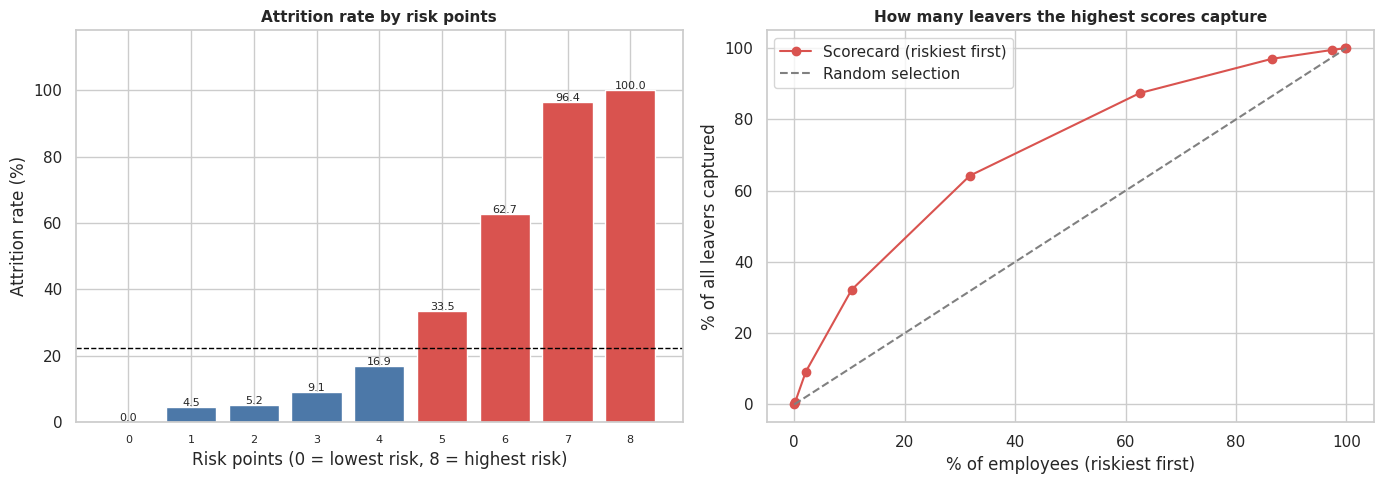

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_rate(axes[0], score, "risk_points", overall, "Attrition rate by risk points")
axes[0].set_xlabel("Risk points (0 = lowest risk, 8 = highest risk)")

curve = pd.concat([pd.DataFrame({"cum_pct_of_employees": [0.0], "cum_pct_of_leavers": [0.0]}),
                   rev[["cum_pct_of_employees", "cum_pct_of_leavers"]]])
axes[1].plot(curve["cum_pct_of_employees"], curve["cum_pct_of_leavers"], marker="o", color=ACCENT, label="Scorecard (riskiest first)")
axes[1].plot([0, 100], [0, 100], linestyle="--", color="grey", label="Random selection")
axes[1].set_xlabel("% of employees (riskiest first)")
axes[1].set_ylabel("% of all leavers captured")
axes[1].set_title("How many leavers the highest scores capture", fontsize=11, fontweight="bold")
axes[1].legend()

fig.tight_layout()
savefig(fig, "04_risk_scorecard")
plt.show()

## 3. Risk bands

In [6]:
bands = rate_table(df, "risk_band")
bands["pct_of_employees"] = (100 * bands["employees"] / len(df)).round(1)
bands["pct_of_leavers"] = (100 * bands["leavers"] / leavers).round(1)
bands = bands[["risk_band", "employees", "pct_of_employees", "leavers", "pct_of_leavers", "attrition_rate_pct", "lift"]]
save_table(bands, "scorecard_bands")
bands

,risk_band,employees,pct_of_employees,leavers,pct_of_leavers,attrition_rate_pct,lift
0,1. Low (0-2),1349,13.5,67,3.0,4.97,0.22
1,2. Medium (3-4),5467,54.7,737,32.8,13.48,0.60
2,3. High (5-8),3184,31.8,1443,64.2,45.32,2.02


In [7]:
top = df[df["risk_points"] >= 6]
display(Markdown(
    f"Employees with **6 or more points**: {len(top):,} ({len(top) / len(df) * 100:.1f}% of staff), "
    f"attrition rate **{top['attrition_flag'].mean() * 100:.1f}%**, "
    f"{top['attrition_flag'].sum() / leavers * 100:.1f}% of all leavers."))

Employees with **6 or more points**: 1,039 (10.4% of staff), attrition rate **69.7%**, 32.2% of all leavers.

## 4. Does the scorecard hold in every department?

In [8]:
check = (df.pivot_table(index="department", columns="risk_band", values="attrition_flag", aggfunc="mean") * 100).round(1)
check

risk_band,1. Low (0-2),2. Medium (3-4),3. High (5-8)
department,,,
Cyber Security,4.9,15.1,45.9
Data Science,4.1,14.2,45.4
IT Services,3.7,12.2,47.4
Network Administration,5.2,13.4,41.1
Software Development,7.1,12.5,46.8


The ordering Low < Medium < High holds in every department, so the pattern is not caused by one group.

## 5. Reference: how does it compare with a model?

Logistic regression is trained on 75% of employees and tested on the other 25%. AUC measures how well a score separates leavers from stayers (0.5 = random, 1.0 = perfect). The scorecard thresholds were set on the full data, so its AUC is slightly optimistic. This is a reference check, not a claim of predictive accuracy.

In [9]:
y = df["attrition_flag"]
num_features = ["age", "distance_from_home", "environment_satisfaction", "salary", "job_involvement", "job_level",
                "job_satisfaction", "companies_worked_before", "salary_hike_pct", "total_experience_years",
                "work_life_balance", "years_at_company", "years_in_role", "years_since_promotion"]
cat_features = ["business_travel", "department", "education", "gender", "job_role", "marital_status", "overtime"]

X_all = pd.get_dummies(df[num_features + cat_features], drop_first=True, dtype=float)
X_all = (X_all - X_all.mean()) / X_all.std()
X_flags = df[rf_cols].astype(float)

idx_train, idx_test = train_test_split(df.index, test_size=0.25, random_state=42, stratify=y)

def holdout_auc(X):
    model = LogisticRegression(max_iter=2000).fit(X.loc[idx_train], y.loc[idx_train])
    return roc_auc_score(y.loc[idx_test], model.predict_proba(X.loc[idx_test])[:, 1])

auc = pd.DataFrame({
    "approach": ["Risk points (sum of 8 flags)", "Logistic regression on the 8 flags", "Logistic regression on all columns"],
    "auc_on_test_rows": [roc_auc_score(y.loc[idx_test], df.loc[idx_test, "risk_points"]),
                         holdout_auc(X_flags), holdout_auc(X_all)],
}).round(3)
save_table(auc, "scorecard_vs_model_auc")
auc

,approach,auc_on_test_rows
0,Risk points (sum of 8 flags),0.772
1,Logistic regression on the 8 flags,0.791
2,Logistic regression on all columns,0.749


In [10]:
a = auc.set_index("approach")["auc_on_test_rows"]
display(Markdown(
    f"The simple sum of eight rules (AUC **{a.iloc[0]:.2f}**) separates leavers about as well as a logistic regression on every column (**{a.iloc[2]:.2f}**) "
    f"and slightly less well than a logistic regression on the same eight flags (**{a.iloc[1]:.2f}**). "
    f"Employee_ID is not used in any of them."))

The simple sum of eight rules (AUC **0.77**) separates leavers about as well as a logistic regression on every column (**0.75**) and slightly less well than a logistic regression on the same eight flags (**0.79**). Employee_ID is not used in any of them.

## 6. Export for Power BI

In [11]:
df.to_csv(PROCESSED / "hr_attrition_scored.csv", index=False)
print("hr_attrition_scored.csv:", df.shape)
df.head()

hr_attrition_scored.csv: (10000, 45)


,employee_id,age,attrition,business_travel,department,distance_from_home,education,environment_satisfaction,gender,salary,job_involvement,job_level,job_role,job_satisfaction,marital_status,companies_worked_before,overtime,salary_hike_pct,total_experience_years,work_life_balance,years_at_company,years_in_role,years_since_promotion,attrition_flag,flag_tenure_gt_experience,flag_role_gt_tenure,flag_promotion_gt_tenure,flag_experience_gt_working_age,any_data_issue,age_band,salary_band,tenure_band,distance_band,promotion_band,salary_hike_band,rf_low_environment_satisfaction,rf_low_work_life_balance,rf_low_job_involvement,rf_low_job_satisfaction,rf_no_recent_promotion,rf_long_distance,rf_frequent_travel,rf_overtime,risk_points,risk_band
0,1,56,Yes,Travel Rarely,Network Administration,24,Graduation,5,Male,186630,2,6,Manager,4,Married,7,Yes,85,9,1,7,2,4,1,0,0,0,0,0,5. 55+,5. 150k+,4. 6-7 yrs,3. 20-29,3. 4-5 yrs,4. 75-100%,0,1,1,0,1,1,0,1,5,3. High (5-8)
1,2,46,Yes,Travel Rarely,Software Development,45,Degree,5,Male,78553,4,5,Help Desk,2,Divorced,3,No,22,18,4,1,2,0,1,0,1,0,0,1,4. 45-54,2. 60k-90k,1. 0-1 yrs,5. 40+,1. 0-1 yrs,1. 0-24%,0,0,0,1,0,1,0,0,2,1. Low (0-2)
2,3,32,No,No Travel,Data Science,30,Master's,3,Female,175003,1,4,HR,2,Single,2,Yes,100,0,4,5,5,8,0,1,0,1,0,1,2. 25-34,5. 150k+,3. 4-5 yrs,4. 30-39,4. 6-8 yrs,4. 75-100%,1,0,1,1,1,1,0,1,6,3. High (5-8)
3,4,60,Yes,Travel Frequently,Data Science,42,Graduation,2,Female,100795,2,8,Help Desk,3,Married,5,No,72,17,2,1,7,3,1,0,1,1,0,1,5. 55+,3. 90k-120k,1. 0-1 yrs,5. 40+,2. 2-3 yrs,3. 50-74%,1,1,1,0,1,1,1,0,6,3. High (5-8)
4,5,25,No,No Travel,Network Administration,26,Graduation,4,Female,75256,1,2,Director,4,Single,9,No,21,12,5,7,2,4,0,0,0,0,1,1,2. 25-34,2. 60k-90k,4. 6-7 yrs,3. 20-29,3. 4-5 yrs,1. 0-24%,0,0,1,0,1,1,0,0,3,2. Medium (3-4)


## 7. Recommendations

In [12]:
def pct(mask):
    return df.loc[mask, "attrition_flag"].mean() * 100

top6 = df[df["risk_points"] >= 6]
high = bands.set_index("risk_band").loc["3. High (5-8)"]
low = bands.set_index("risk_band").loc["1. Low (0-2)"]

recs = [
    f"1. **Start retention check-ins with the highest scores.** Employees with 6 or more points are {len(top6) / len(df) * 100:.1f}% of staff, have {top6['attrition_flag'].mean() * 100:.1f}% attrition and account for {top6['attrition_flag'].sum() / leavers * 100:.1f}% of leavers. The whole High band (5 or more points) is {high['pct_of_employees']:.1f}% of staff but {high['pct_of_leavers']:.1f}% of leavers, with {high['attrition_rate_pct']:.1f}% attrition against {low['attrition_rate_pct']:.1f}% in the Low band.",
    f"2. **Fix promotion gaps.** Attrition is {pct(df.years_since_promotion >= 2):.1f}% when the last promotion was 2 or more years ago, against {pct(df.years_since_promotion < 2):.1f}% for less than 2 years. Review anyone passing the 2-year mark.",
    f"3. **Improve the work environment and work-life balance.** Attrition is {pct(df.environment_satisfaction <= 3):.1f}% when environment satisfaction is 3 or lower and {pct(df.work_life_balance <= 2):.1f}% when work-life balance is 2 or lower.",
    f"4. **Support engagement.** Job involvement of 2 or lower goes with {pct(df.job_involvement <= 2):.1f}% attrition, against {pct(df.job_involvement >= 3):.1f}% for higher scores.",
    f"5. **Offer flexible or remote options for long commutes.** Attrition is {pct(df.distance_from_home >= 10):.1f}% at a distance of 10 or more, against {pct(df.distance_from_home < 10):.1f}% below 10.",
    f"6. **Limit frequent business travel and overtime where possible.** Frequent travel goes with {pct(df.business_travel == 'Travel Frequently'):.1f}% attrition and overtime with {pct(df.overtime == 'Yes'):.1f}%.",
    "7. **Do not rely on pay changes alone.** In this data, salary, salary hike, age, gender and department show no reliable link with attrition.",
]
display(Markdown("\n\n".join(recs)))

1. **Start retention check-ins with the highest scores.** Employees with 6 or more points are 10.4% of staff, have 69.7% attrition and account for 32.2% of leavers. The whole High band (5 or more points) is 31.8% of staff but 64.2% of leavers, with 45.3% attrition against 5.0% in the Low band.

2. **Fix promotion gaps.** Attrition is 26.1% when the last promotion was 2 or more years ago, against 10.1% for less than 2 years. Review anyone passing the 2-year mark.

3. **Improve the work environment and work-life balance.** Attrition is 29.9% when environment satisfaction is 3 or lower and 31.0% when work-life balance is 2 or lower.

4. **Support engagement.** Job involvement of 2 or lower goes with 31.6% attrition, against 16.2% for higher scores.

5. **Offer flexible or remote options for long commutes.** Attrition is 25.8% at a distance of 10 or more, against 7.4% below 10.

6. **Limit frequent business travel and overtime where possible.** Frequent travel goes with 34.3% attrition and overtime with 26.2%.

7. **Do not rely on pay changes alone.** In this data, salary, salary hike, age, gender and department show no reliable link with attrition.